# Lab — MLOps Deployment Workflow (DEV → PROD)

**Project:** Telecom customer churn prediction  
**Purpose:** Build, evaluate, serialize, validate, and promote a machine-learning pipeline using a reproducible development workflow.

This notebook is the executable companion to the supplied `README.md`, `train.py`, `check_model.py`, and `data/churn.csv`. The supplied ZIP did not include an `.ipynb`, so this notebook has been created from the README's stated pipeline and checkpoints.

## Learning outcomes

By the end, you should be able to:

1. Explain the ML pipeline and why preprocessing belongs inside a scikit-learn `Pipeline`.
2. Inspect an imbalanced classification dataset and define a defensible train/test split.
3. Evaluate a baseline model with cross-validation and a held-out test set.
4. Save and reload a complete pipeline plus metadata.
5. Apply a Gatekeeper check before promotion.
6. Compare a stronger model and raise the acceptance threshold.
7. Explain how branches, pull requests, clean environment rebuilds, and reviews support DEV → PROD.

> **Important distinction:** running this notebook validates the technical workflow locally. The two actual GitHub pull requests, review comments, collaborator roles, and merges are team actions and cannot be created by a local notebook.

## 1. Project setup and imports

Run this notebook from the project root (the directory containing `train.py` and `data/`). The relative paths below are intentionally aligned with the command-line workflow in the README.

In [1]:
from pathlib import Path
import json
import sys
import warnings

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn
from sklearn.metrics import (
    ConfusionMatrixDisplay, RocCurveDisplay, classification_report,
    roc_auc_score, accuracy_score, precision_score, recall_score, f1_score
)

PROJECT_ROOT = Path.cwd()
if not (PROJECT_ROOT / "train.py").exists():
    # Also support opening the notebook while the current directory is notebooks/.
    PROJECT_ROOT = PROJECT_ROOT.parent
if not (PROJECT_ROOT / "train.py").exists():
    raise FileNotFoundError("Open this notebook from the completed project directory.")

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from train import load_data, make_pipeline, train
from check_model import main as gatekeeper_check

print("Project root:", PROJECT_ROOT)
print("Python:", sys.version.split()[0])
print("pandas:", pd.__version__)
print("scikit-learn:", sklearn.__version__)
print("joblib:", joblib.__version__)

Project root: /Users/theophiluskobinasarpey/Documents/DSML_SEP2026 | IRONHACK/Week 8/Day 2/lab-mlops-deploy-prod-to-dev
Python: 3.14.6
pandas: 3.1.0
scikit-learn: 1.9.1
joblib: 1.5.3


## 2. Understand the data and prediction task

The target is `Churn?`. The source uses the strings `True.` and `False.`; we encode these as 1 and 0. The dataset has customer service and telephone usage attributes.

The supplied starter excludes `Phone`, `Area Code`, and `State` from predictors. `Phone` is an identifier and should not be treated as a customer-behaviour signal. We retain the two binary plan variables and numerical usage variables.

In [2]:
data_path = PROJECT_ROOT / "data" / "churn.csv"
raw = pd.read_csv(data_path)

print(f"Rows: {raw.shape[0]:,} | Columns: {raw.shape[1]}")
display(raw.head())
display(raw.dtypes.rename("dtype").to_frame())

Rows: 3,333 | Columns: 21


,State,Account Length,Area Code,Phone,Int'l Plan,VMail Plan,VMail Message,Day Mins,Day Calls,Day Charge,...,Eve Calls,Eve Charge,Night Mins,Night Calls,Night Charge,Intl Mins,Intl Calls,Intl Charge,CustServ Calls,Churn?
0,KS,128,415,382-4657,no,yes,25,265.1,110,45.07,...,99,16.78,244.7,91,11.01,10.0,3,2.70,1,False.
1,OH,107,415,371-7191,no,yes,26,161.6,123,27.47,...,103,16.62,254.4,103,11.45,13.7,3,3.70,1,False.
2,NJ,137,415,358-1921,no,no,0,243.4,114,41.38,...,110,10.30,162.6,104,7.32,12.2,5,3.29,0,False.
3,OH,84,408,375-9999,yes,no,0,299.4,71,50.90,...,88,5.26,196.9,89,8.86,6.6,7,1.78,2,False.
4,OK,75,415,330-6626,yes,no,0,166.7,113,28.34,...,122,12.61,186.9,121,8.41,10.1,3,2.73,3,False.


,dtype
State,str
Account Length,int64
Area Code,int64
Phone,str
Int'l Plan,str
VMail Plan,str
VMail Message,int64
Day Mins,float64
Day Calls,int64
Day Charge,float64


In [3]:
# Check data quality before modelling.
quality = pd.DataFrame({
    "missing_values": raw.isna().sum(),
    "unique_values": raw.nunique(dropna=False),
})
display(quality)

target_counts = raw["Churn?"].value_counts().rename(index={"False.": "No churn", "True.": "Churn"})
display(target_counts.to_frame("customers"))
print(f"Churn prevalence: {(raw['Churn?'] == 'True.').mean():.1%}")

,missing_values,unique_values
State,0,51
Account Length,0,212
Area Code,0,3
Phone,0,3333
Int'l Plan,0,2
VMail Plan,0,2
VMail Message,0,46
Day Mins,0,1667
Day Calls,0,119
Day Charge,0,1667


,customers
Churn?,
No churn,2850
Churn,483


Churn prevalence: 14.5%


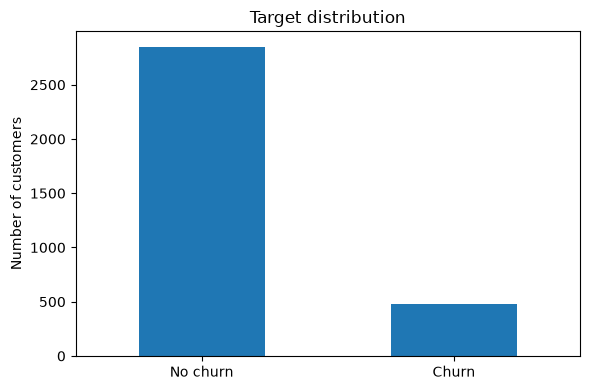

In [4]:
# A simple class-balance chart helps explain why accuracy alone can mislead.
ax = target_counts.plot(kind="bar", figsize=(6, 4), rot=0)
ax.set_title("Target distribution")
ax.set_xlabel("")
ax.set_ylabel("Number of customers")
plt.tight_layout()
plt.show()

### Data-quality interpretation

- Confirm whether there are missing values; the supplied dataset is expected to be complete.
- Churn is the minority class (roughly 14.5%). A classifier that predicts “no churn” for everyone would already achieve high accuracy, while being useless at identifying churn.
- We therefore use **ROC-AUC** as the primary model-selection metric, and inspect precision/recall as supplementary measures.

## 3. Define the split and preprocessing

We use a stratified 80/20 train/test split with `random_state=42`. Stratification preserves approximately the same churn prevalence in both partitions.

Preprocessing is fitted *inside* the pipeline:
- `OneHotEncoder` handles the binary categorical plan columns.
- `StandardScaler` standardizes numerical variables for Logistic Regression.
- `ColumnTransformer` applies the right transformation to each column group.

Putting preprocessing inside the pipeline prevents leakage during cross-validation: every fold learns its own transformations using only that fold's training data.

In [5]:
X_train, X_test, y_train, y_test = load_data(str(data_path))
print("Training rows:", len(X_train), "| Test rows:", len(X_test))
print("Training churn rate:", f"{y_train.mean():.3%}")
print("Test churn rate:", f"{y_test.mean():.3%}")
print("Predictor columns:", list(X_train.columns))

Training rows: 2666 | Test rows: 667
Training churn rate: 14.479%
Test churn rate: 14.543%
Predictor columns: ['Account Length', "Int'l Plan", 'VMail Plan', 'VMail Message', 'Day Mins', 'Day Calls', 'Day Charge', 'Eve Mins', 'Eve Calls', 'Eve Charge', 'Night Mins', 'Night Calls', 'Night Charge', 'Intl Mins', 'Intl Calls', 'Intl Charge', 'CustServ Calls']


## 4. Round 1 — baseline Logistic Regression

The training function performs five-fold cross-validation on the training partition, fits the pipeline on all training rows, and evaluates the final model once on the untouched test partition.

The expected checkpoint from the original README is approximately:
- mean CV ROC-AUC: **0.816**
- holdout test ROC-AUC: **0.818**

In [6]:
baseline_pipeline, baseline_metadata, split_data = train(
    model_name="logistic", data_path=str(data_path)
)
baseline_metadata

Saved models/churn_pipeline.joblib: LogisticRegression, cv_auc 0.816, test_auc 0.818


{'model': 'LogisticRegression',
 'model_name': 'logistic',
 'trained_at': '2026-11-03T19:48:25+00:00',
 'features': ['Account Length',
  "Int'l Plan",
  'VMail Plan',
  'VMail Message',
  'Day Mins',
  'Day Calls',
  'Day Charge',
  'Eve Mins',
  'Eve Calls',
  'Eve Charge',
  'Night Mins',
  'Night Calls',
  'Night Charge',
  'Intl Mins',
  'Intl Calls',
  'Intl Charge',
  'CustServ Calls'],
 'cv_auc': 0.816174833937992,
 'cv_auc_std': 0.033387108840154375,
 'test_auc': 0.8179960209802857,
 'python': '3.14.6',
 'scikit-learn': '1.9.1',
 'pandas': '3.1.0',
 'joblib': '1.5.3',
 'random_state': 42}

In [9]:
import os

# Train from the project root so artifacts are saved where the Gatekeeper expects them.
previous_cwd = Path.cwd()
try:
    os.chdir(PROJECT_ROOT)
    baseline_pipeline, baseline_metadata, split_data = train(
        model_name="logistic", data_path=str(data_path)
    )

    # Gatekeeper check: reload the serialized model and metadata from disk.
    baseline_check_status = gatekeeper_check(min_auc=0.80)
finally:
    os.chdir(previous_cwd)
assert baseline_check_status == 0, "Round 1 Gatekeeper check did not pass."

Saved models/churn_pipeline.joblib: LogisticRegression, cv_auc 0.816, test_auc 0.818
Model: LogisticRegression | CV AUC: 0.816 | trained: 2026-11-03T19:50:33+00:00 | scikit-learn: 1.9.1
CHECK PASSED: test ROC AUC 0.818 (minimum 0.80)


In [10]:
# Additional diagnostic metrics. The default 0.5 threshold is shown for context;
# the lab's acceptance gate is ROC-AUC, not a fixed classification threshold.
_, X_test, _, y_test = load_data(str(data_path))
baseline_prob = baseline_pipeline.predict_proba(X_test)[:, 1]
baseline_pred = (baseline_prob >= 0.5).astype(int)

baseline_metrics = {
    "CV ROC-AUC": baseline_metadata["cv_auc"],
    "Test ROC-AUC": roc_auc_score(y_test, baseline_prob),
    "Accuracy at 0.5": accuracy_score(y_test, baseline_pred),
    "Precision at 0.5": precision_score(y_test, baseline_pred, zero_division=0),
    "Recall at 0.5": recall_score(y_test, baseline_pred, zero_division=0),
    "F1 at 0.5": f1_score(y_test, baseline_pred, zero_division=0),
}
display(pd.Series(baseline_metrics, name="Logistic Regression").to_frame())
print(classification_report(y_test, baseline_pred, target_names=["No churn", "Churn"], zero_division=0))

,Logistic Regression
CV ROC-AUC,0.816175
Test ROC-AUC,0.817996
Accuracy at 0.5,0.860570
Precision at 0.5,0.545455
Recall at 0.5,0.247423
F1 at 0.5,0.340426


              precision    recall  f1-score   support

    No churn       0.88      0.96      0.92       570
       Churn       0.55      0.25      0.34        97

    accuracy                           0.86       667
   macro avg       0.71      0.61      0.63       667
weighted avg       0.83      0.86      0.84       667



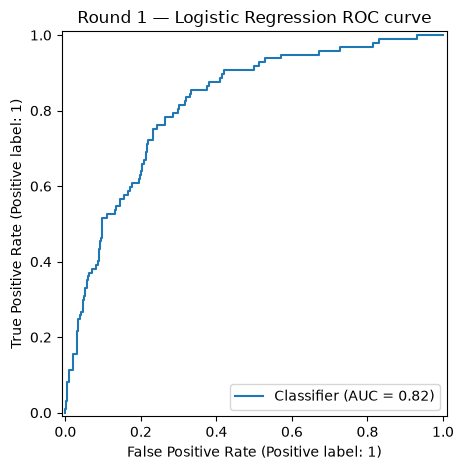

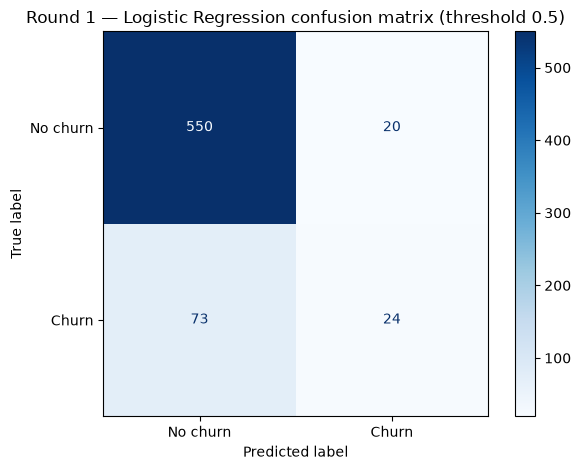

In [11]:
RocCurveDisplay.from_predictions(y_test, baseline_prob)
plt.title("Round 1 — Logistic Regression ROC curve")
plt.tight_layout()
plt.show()

ConfusionMatrixDisplay.from_predictions(
    y_test, baseline_pred, display_labels=["No churn", "Churn"], cmap="Blues"
)
plt.title("Round 1 — Logistic Regression confusion matrix (threshold 0.5)")
plt.tight_layout()
plt.show()

### Round 1 interpretation

The baseline should reproduce the README checkpoint to three decimal places in the pinned environment. AUC around 0.818 indicates useful ranking ability, but it does not mean 81.8% of customers are classified correctly. The confusion matrix and precision/recall depend on the chosen decision threshold.

The pipeline and metadata are saved under `models/`. This folder is intentionally excluded from Git: the Gatekeeper must be able to rebuild the artifacts from tracked code, data, and dependency pins.

## 5. Round 2 — improve the model with Random Forest

The README suggests a Random Forest with 200 trees and `random_state=42`. We keep the same data split, features, cross-validation design, and ROC-AUC metric so the comparison is fair.

Random Forest does not require feature scaling, but we retain the same preprocessing pipeline for a consistent, single-artifact workflow. The model is trained on the same training partition; the test set remains a final holdout.

In [12]:
forest_pipeline, forest_metadata, split_data = train(
    model_name="random_forest", data_path=str(data_path)
)
forest_metadata

Saved models/churn_pipeline.joblib: RandomForestClassifier, cv_auc 0.920, test_auc 0.888


{'model': 'RandomForestClassifier',
 'model_name': 'random_forest',
 'trained_at': '2026-11-03T19:51:00+00:00',
 'features': ['Account Length',
  "Int'l Plan",
  'VMail Plan',
  'VMail Message',
  'Day Mins',
  'Day Calls',
  'Day Charge',
  'Eve Mins',
  'Eve Calls',
  'Eve Charge',
  'Night Mins',
  'Night Calls',
  'Night Charge',
  'Intl Mins',
  'Intl Calls',
  'Intl Charge',
  'CustServ Calls'],
 'cv_auc': 0.9195948788054051,
 'cv_auc_std': 0.015084930287867572,
 'test_auc': 0.8883704105624887,
 'python': '3.14.6',
 'scikit-learn': '1.9.1',
 'pandas': '3.1.0',
 'joblib': '1.5.3',
 'random_state': 42}

In [15]:
# Round 2 acceptance gate: the README asks the team to raise MIN_AUC to 0.85.
round2_previous_cwd = Path.cwd()
try:
	os.chdir(PROJECT_ROOT)
	forest_pipeline, forest_metadata, split_data = train(
		model_name="random_forest", data_path=str(data_path)
	)
	forest_check_status = gatekeeper_check(min_auc=0.85)
finally:
	os.chdir(round2_previous_cwd)

assert forest_check_status == 0, "Round 2 Gatekeeper check did not pass."

Saved models/churn_pipeline.joblib: RandomForestClassifier, cv_auc 0.920, test_auc 0.888
Model: RandomForestClassifier | CV AUC: 0.920 | trained: 2026-11-03T19:52:26+00:00 | scikit-learn: 1.9.1
CHECK PASSED: test ROC AUC 0.888 (minimum 0.85)


In [16]:
# Compare like-for-like metrics on the same held-out test partition.
_, X_test, _, y_test = load_data(str(data_path))
forest_prob = forest_pipeline.predict_proba(X_test)[:, 1]
forest_pred = (forest_prob >= 0.5).astype(int)

comparison = pd.DataFrame({
    "Logistic Regression": {
        "Mean 5-fold CV ROC-AUC": baseline_metadata["cv_auc"],
        "Holdout test ROC-AUC": baseline_metadata["test_auc"],
        "Accuracy (threshold 0.5)": accuracy_score(y_test, baseline_prob >= 0.5),
        "Precision (threshold 0.5)": precision_score(y_test, baseline_prob >= 0.5, zero_division=0),
        "Recall (threshold 0.5)": recall_score(y_test, baseline_prob >= 0.5, zero_division=0),
    },
    "Random Forest": {
        "Mean 5-fold CV ROC-AUC": forest_metadata["cv_auc"],
        "Holdout test ROC-AUC": forest_metadata["test_auc"],
        "Accuracy (threshold 0.5)": accuracy_score(y_test, forest_pred),
        "Precision (threshold 0.5)": precision_score(y_test, forest_pred, zero_division=0),
        "Recall (threshold 0.5)": recall_score(y_test, forest_pred, zero_division=0),
    },
})
display(comparison.round(3))
print("CV AUC improvement:", f"{forest_metadata['cv_auc'] - baseline_metadata['cv_auc']:+.3f}")
print("Test AUC change:", f"{forest_metadata['test_auc'] - baseline_metadata['test_auc']:+.3f}")

,Logistic Regression,Random Forest
Mean 5-fold CV ROC-AUC,0.816,0.920
Holdout test ROC-AUC,0.818,0.888
Accuracy (threshold 0.5),0.861,0.942
Precision (threshold 0.5),0.545,0.903
Recall (threshold 0.5),0.247,0.670


CV AUC improvement: +0.103
Test AUC change: +0.070


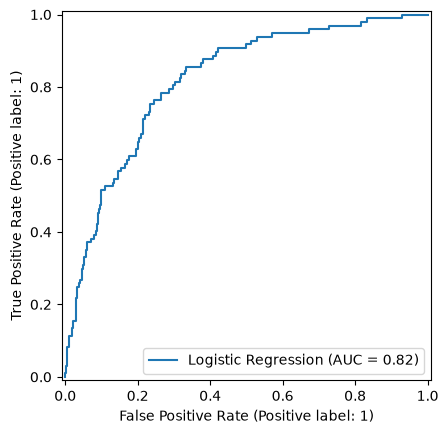

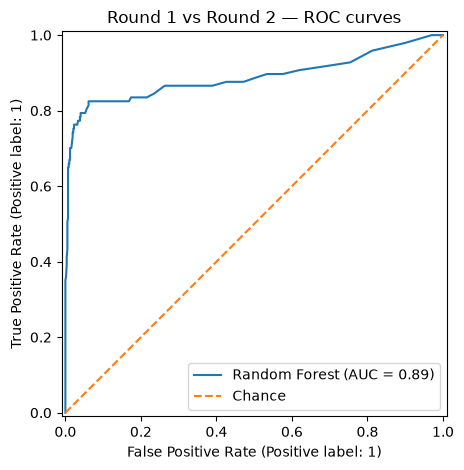

In [17]:
RocCurveDisplay.from_predictions(y_test, baseline_prob, name="Logistic Regression")
RocCurveDisplay.from_predictions(y_test, forest_prob, name="Random Forest")
plt.plot([0, 1], [0, 1], linestyle="--", label="Chance")
plt.title("Round 1 vs Round 2 — ROC curves")
plt.legend()
plt.tight_layout()
plt.show()

### Round 2 interpretation

The expected result is a CV ROC-AUC around **0.920** and test ROC-AUC around **0.889**. This is a substantial improvement over the baseline on cross-validation and the held-out test set.

The stronger model passes the raised 0.85 test-AUC gate. This does not automatically make it production-ready: model calibration, operating thresholds, false-positive/false-negative costs, fairness, and data drift would need separate investigation.

## 6. What exactly is being shipped?

The saved `.joblib` artifact contains the **entire fitted sklearn pipeline**, not just the estimator. This matters because inference must apply the same encodings and transformations that were learned during training.

The JSON metadata records the estimator, feature list, timestamp, CV/test scores, and relevant software versions. The check script reloads both files and verifies:
1. The model's expected feature columns match the current test input.
2. Predicted scores are valid finite probabilities in [0, 1].
3. Holdout ROC-AUC meets the agreed minimum.

The final model in `models/` is now the Random Forest because Round 2 training overwrote the Round 1 local artifact. In a real Git workflow, the two model versions are represented by different code branches/commits and rebuilt by the Gatekeeper.

In [18]:
with open(PROJECT_ROOT / "models" / "churn_pipeline.json", encoding="utf-8") as f:
    final_metadata = json.load(f)
reloaded_pipeline = joblib.load(PROJECT_ROOT / "models" / "churn_pipeline.joblib")

assert final_metadata["model"] == "RandomForestClassifier"
assert final_metadata["cv_auc"] > baseline_metadata["cv_auc"]
assert final_metadata["test_auc"] >= 0.85
assert reloaded_pipeline.predict_proba(X_test.iloc[:5])[:, 1].shape == (5,)

print("Artifact reload verified.")
print(json.dumps(final_metadata, indent=2))

Artifact reload verified.
{
  "model": "RandomForestClassifier",
  "model_name": "random_forest",
  "trained_at": "2026-11-03T19:52:26+00:00",
  "features": [
    "Account Length",
    "Int'l Plan",
    "VMail Plan",
    "VMail Message",
    "Day Mins",
    "Day Calls",
    "Day Charge",
    "Eve Mins",
    "Eve Calls",
    "Eve Charge",
    "Night Mins",
    "Night Calls",
    "Night Charge",
    "Intl Mins",
    "Intl Calls",
    "Intl Charge",
    "CustServ Calls"
  ],
  "cv_auc": 0.9195948788054051,
  "cv_auc_std": 0.015084930287867572,
  "test_auc": 0.8883704105624887,
  "python": "3.14.6",
  "scikit-learn": "1.9.1",
  "pandas": "3.1.0",
  "joblib": "1.5.3",
  "random_state": 42
}


## 7. DEV → PROD: the collaboration and release process

### Round 1 — `first-model`

**Developer**
1. Clone the Gatekeeper's repository; do not run `git init`.
2. Create `first-model`.
3. Add `train.py`, `check_model.py`, `data/churn.csv`, `requirements.txt`, `.gitignore`, and README.
4. Create a virtual environment, install dependencies, run `python train.py` and `python check_model.py`.
5. Commit and push only the branch; open a PR into `main`.

**Gatekeeper**
1. Review the PR and leave at least one meaningful comment.
2. Rebuild from a fresh clone and fresh virtual environment using only `requirements.txt`.
3. Run training and the check.
4. Merge only after the check passes and the repository contains no `.venv/`, `models/`, caches, or secrets.

### Round 2 — `better-model`

Switch roles. The new Developer branches from updated `main`, changes the estimator to Random Forest, and reports the old and new CV-AUC in the PR. The new Gatekeeper requests the acceptance threshold be raised to 0.85, rebuilds the environment, runs the check, and merges only if the model improves CV-AUC and passes the stricter check.

### Useful Git commands

```bash
git clone <repo-url>
cd <repo>
git checkout -b first-model
# Add project files, then:
git add train.py check_model.py data/churn.csv requirements.txt .gitignore README.md
git commit -m "Ship reproducible baseline churn model"
git push -u origin first-model
# Open PR: first-model -> main

# After Round 1 has been merged, switch roles:
git checkout main
git pull
git checkout -b better-model
python train.py --model random_forest
python check_model.py --min-auc 0.85
git add train.py check_model.py README.md
git commit -m "Improve churn model with random forest"
git push -u origin better-model
# Open PR: better-model -> main
```

> The GitHub PRs, reviews, collaborator permissions, and merges are not simulated here. The lab is only complete when both real PRs are reviewed and merged, as required by the original submission brief.

## 8. Reproducibility and final checklist

- [ ] A fresh environment can be created from the pinned `requirements.txt`.
- [ ] The training script runs without relying on notebook variables.
- [ ] The complete preprocessing/model pipeline is saved and reloadable.
- [ ] The Gatekeeper check passes for the baseline at 0.80.
- [ ] The Random Forest improves mean CV ROC-AUC and passes the 0.85 gate.
- [ ] `.venv/`, `models/`, caches, notebook checkpoints, and secrets are ignored by Git.
- [ ] README contains the purpose, environment, commands, expected results, and limitations.
- [ ] Two real GitHub PRs exist, each with a review comment and merge.